# Relative light yield

Step 1: distribution of the waveform integral for each channel and field.

The integral is the `integral_50_500` column of the `fprompt_<channel>_*.csv` files
that `coincidence/only_selection` and `coincidence/plot_wfs_coincidence` write next to
the mean waveforms: one row per waveform that passed the selection. It is the
trapezoid of ADC - baseline over samples [50, 500) (`pds/integrals.py`), in ADC x ticks
(1 tick = 16 ns). Rows are weighted by `multiplicity`, as the mean waveform counts
them (always 1 for `only_selection`).

In [5]:
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import dunestyle.matplotlib as dunestyle

# repository root: the first parent folder that holds pds/
REPO_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pds" / "paths.py").exists())
sys.path.insert(0, str(REPO_DIR))
from pds import modules, paths
from pds import runs as pds_runs
from pds.integrals import INTEGRAL_FIRST_SAMPLE, INTEGRAL_LAST_SAMPLE

DUNE plot style enabled


/home/leoperes/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [68]:
run_to_efield = {

    # Zero-field reference
    39510: 0.0,

    # Increasing HV scan
    39511: 0.028571,
    39512: 0.057143,
    39514: 0.085714,
    39515: 0.114286,
    39516: 0.142857,
    39517: 0.171429,
    39518: 0.200000,
    39519: 0.228571,
    39521: 0.257143,
    39522: 0.285714,
    39523: 0.314286,
    39525: 0.342857,
    39526: 0.371429,
    39527: 0.400000,
    39528: 0.428571,
    39529: 0.444857,
   # 39787: 0.5, bad

    # Decreasing HV scan
    39500: 0.444857,
    39501: 0.400000,
    39502: 0.342857,
    39503: 0.285714,
    39504: 0.228571,
    39506: 0.171429,
    39507: 0.114286,
    39508: 0.057143,

    # Higher HV scan
    43380: 0.685,
    43381: 0.685,
    43383: 0.586,
    43384: 0.586,
    43386: 0.771,
    43387: 0.771,
    43389: 0.44,
    43390: 0.44,
    41523: 0.834,

}

# ============================================================
# Sample and settings
# ============================================================

SAMPLE = "coinc_M7-M8_vs_M1-M2_save_M5-M6_a0_r292kV_aux2000_full12000"

path_waveforms = paths.COINC_DIR / SAMPLE

INTEGRAL = f"integral_{INTEGRAL_FIRST_SAMPLE}_{INTEGRAL_LAST_SAMPLE}"  # CSV column
MIN_WAVEFORMS = 1000   # a (channel, run) with fewer selected waveforms is left out
N_BINS = 100

OUT_DIR = paths.OUTPUT_DIR / "analysis" / "relative_ly" / SAMPLE
OUT_DIR.mkdir(parents=True, exist_ok=True)

csv_files = sorted(path_waveforms.glob("fprompt_*_run_*.csv"))
print(f"Found {len(csv_files)} CSV files in {path_waveforms}")

Found 28 CSV files in /home/leoperes/pds_analysis/coincidence/selected_waveforms/coinc_M7-M8_vs_M1-M2_save_M5-M6_a0_r292kV_aux2000_full12000


In [69]:
# fprompt_<channel>_{coincidence|only_selection}_scan_run_<run>_<SAMPLE>.csv
pattern = re.compile(
    r"^fprompt_(?P<channel>\d+)_(?:coincidence|only_selection)_scan_run_"
    r"(?P<run>\d+)_" + re.escape(SAMPLE) + r"\.csv$"
)

integrals = {}   # (channel, run) -> (integral, multiplicity)
too_few = []
for csv_file in csv_files:
    match = pattern.fullmatch(csv_file.name)
    if match is None:
        continue

    channel = int(match["channel"])
    run = int(match["run"])
    if run not in run_to_efield:
        print(f"Run {run} not found in run_to_efield mapping.")
        continue

    df = pd.read_csv(csv_file, usecols=[INTEGRAL, "multiplicity"])
    if len(df) < MIN_WAVEFORMS:
        too_few.append(f"{channel} run {run:06d} ({len(df)})")
        continue
    integrals[(channel, run)] = (df[INTEGRAL].to_numpy(), df["multiplicity"].to_numpy())

channels = sorted({channel for channel, _ in integrals})
runs = sorted({run for _, run in integrals}, key=run_to_efield.get)
if too_few:
    print(f"Left out (< {MIN_WAVEFORMS} waveforms): {', '.join(too_few)}")

# selected waveforms per channel (rows) and field in kV/cm (columns)
counts = pd.Series(
    {(channel, run_to_efield[run]): int(w.sum()) for (channel, run), (_, w) in integrals.items()}
).unstack().astype("Int64")
counts.index.name, counts.columns.name = "channel", "E [kV/cm]"
counts

E [kV/cm],0.000000,0.028571,0.057143,0.114286,0.285714,0.586000,0.834000
channel,,,,,,,
2050,12180,13068,12654,11630,9702,7967,6352
2051,10065,10733,10456,9541,7958,6356,5096
2060,7958,9372,9178,8527,7655,6300,5460
2061,6051,7104,7169,6740,6043,5174,4493


In [70]:
# One blue, light -> dark with field (ordered by field, not by its value, so the
# low fields stay apart). Keyed by run: a field has the same color in every panel.
FIELD_RAMP = LinearSegmentedColormap.from_list("field", [
    "#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#2a78d6",
    "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b",
])
run_color = {run: FIELD_RAMP(f) for run, f in zip(runs, np.linspace(0, 1, len(runs)))}

SCALE = 1e3   # plot the integral in 10^3 ADC x ticks


def common_bins(keys):
    """N_BINS bins over the 0.1-99.9 % range of the integrals of every key."""
    values = np.concatenate([integrals[key][0] for key in keys])
    low, high = np.quantile(values, [0.001, 0.999])
    return np.linspace(low, high, N_BINS + 1) / SCALE


def plot_integral(ax, channel, run, bins, **kwargs):
    integral, multiplicity = integrals[(channel, run)]
    ax.hist(
        integral / SCALE,
        bins=bins,
        weights=multiplicity,
        density=True,
        histtype="step",
        linewidth=1.5,
        color=run_color[run],
        **kwargs,
    )


integral_label = (
    f"Integral {INTEGRAL_FIRST_SAMPLE}-{INTEGRAL_LAST_SAMPLE} "
    r"[$10^3$ ADC $\times$ ticks]"
)

## Every channel

One panel per channel, one line per field. Bins are shared by the fields of a channel.

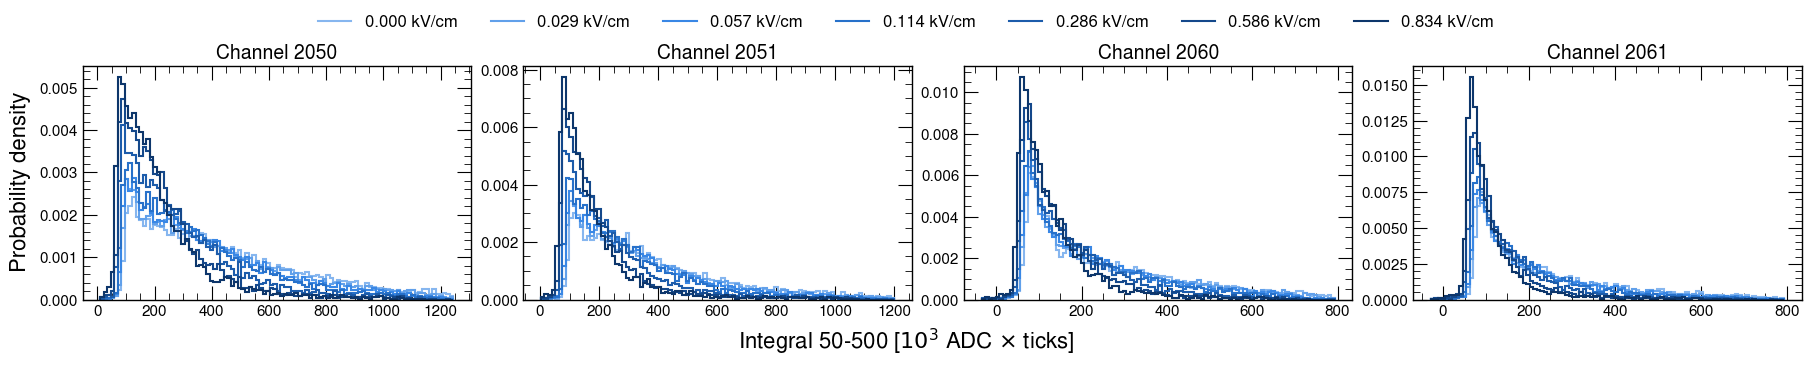

In [71]:
N_COLS = 4
n_rows = -(-len(channels) // N_COLS)
fig, axes = plt.subplots(
    n_rows, N_COLS, figsize=(4.5 * N_COLS, 3.6 * n_rows), dpi=100,
    layout="constrained", squeeze=False,
)

for ax, channel in zip(axes.flat, channels):
    channel_runs = [run for run in runs if (channel, run) in integrals]
    bins = common_bins([(channel, run) for run in channel_runs])
    for run in channel_runs:
        plot_integral(ax, channel, run, bins, label=f"{run_to_efield[run]:.3f} kV/cm")
    ax.set_title(f"Channel {channel}", fontsize=14)
    ax.tick_params(labelsize=11)
    ax.yaxis.get_offset_text().set_fontsize(10)
for ax in axes.flat[len(channels):]:
    ax.set_visible(False)

# one legend for the figure, every field in field order
handles = [plt.Line2D([], [], color=run_color[run], linewidth=1.5) for run in runs]
labels = [f"{run_to_efield[run]:.3f} kV/cm" for run in runs]
fig.legend(handles, labels, loc="outside upper center", ncol=len(runs), fontsize=12)
fig.supxlabel(integral_label, fontsize=16)
fig.supylabel("Probability density", fontsize=16)

fig.savefig(OUT_DIR / "integral_distribution_all_channels.png", dpi=200)
plt.show()

## Selected channels

As in `plot_fprompt.ipynb`: the chosen channels on one plot, line style by channel.

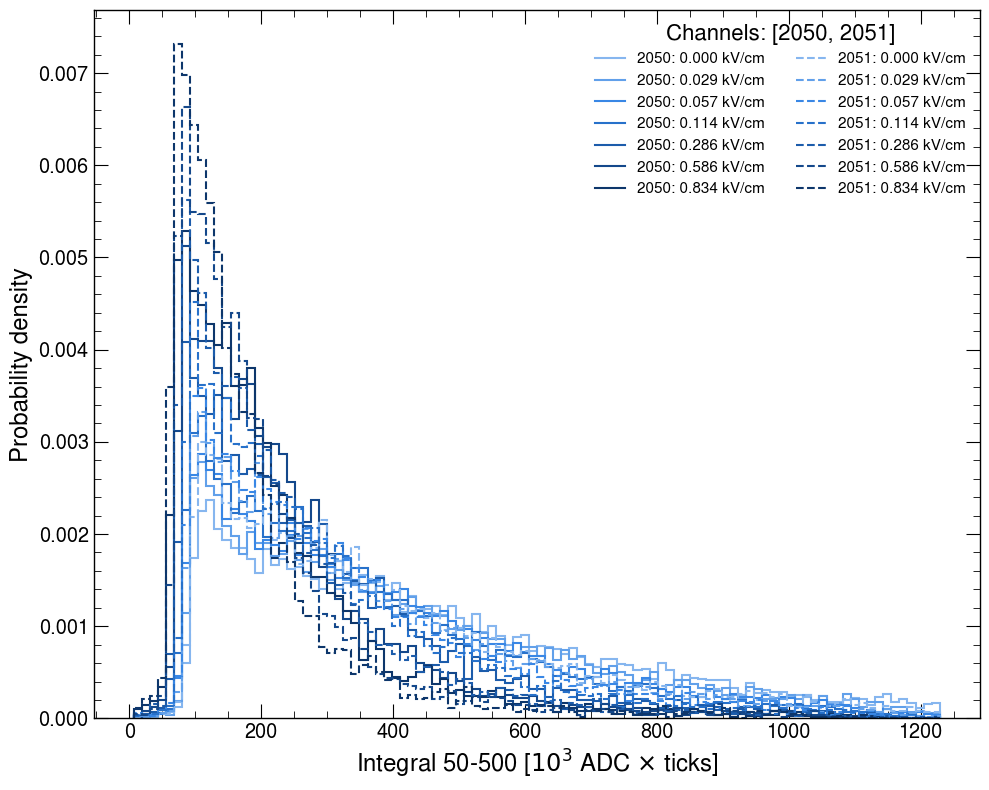

In [74]:
selected_channels = [2050, 2051]
linestyles = ["-", "--", ":", "-."]   # one per channel, so at most 4 channels

keys = [(channel, run) for channel in selected_channels for run in runs
        if (channel, run) in integrals]
bins = common_bins(keys)

fig, ax = plt.subplots(figsize=(10, 8), dpi=100)
handles, labels = [], []
for channel, linestyle in zip(selected_channels, linestyles):
    for run in runs:
        if (channel, run) not in integrals:
            continue
        plot_integral(ax, channel, run, bins, linestyle=linestyle)
        handles.append(plt.Line2D([], [], color=run_color[run], linestyle=linestyle, linewidth=1.5))
        labels.append(f"{channel}: {run_to_efield[run]:.3f} kV/cm")
ax.set_xlabel(integral_label)
ax.set_ylabel("Probability density")
ax.legend(handles, labels, loc="upper right", ncol=len(selected_channels), fontsize=11,
          title=f"Channels: {selected_channels}", title_fontsize=16)
fig.tight_layout()
fig.savefig(OUT_DIR / f"integral_distribution_{'-'.join(map(str, selected_channels))}.png", dpi=300)
plt.show()

## Relative light yield per XA pair

Per channel, $S$ is the mean integral of a run and $S/S_0$ divides it by the mean of the
same channel at 0 kV (run 039510). The mean of `integral_50_500` equals the integral of
the mean waveform, so $S$ is the same quantity as in `analysis/LY_vs_EF/fit_LY_wo_template.py`.
Runs at the same field are averaged.

A pair (M1/M2, M3/M4, M5/M6, M7/M8) is the equal-weight average of its channels at each
field, as `fit_LY_wo_template.py` averages channels. Module M$k$ is channels 20$k$0 and 20$k$1.

- `rel_err`: statistical only, the standard error of each mean propagated through the ratio
  (exactly 0 at 0 kV) and averaged in quadrature over the channels.
- `spread`: max - min of the channel values in the pair. It shows how much the channels disagree.
- `complete`: every channel the pair has at 0 kV is also there at this field. A point without
  them averages fewer channels and is drawn with an open marker.

In [75]:
REFERENCE_RUN = 39510   # 0 kV

# XA pairs: module Mk -> channels 20k0 and 20k1 (pds/modules.py)
pairs = {
    f"M{k}/M{k + 1}": [modules.channel(f"M{m}", array) for m in (k, k + 1) for array in (1, 2)]
    for k in (1, 3, 5, 7)
}

records = []
for (channel, run), (integral, multiplicity) in integrals.items():
    mean = np.average(integral, weights=multiplicity)
    std = np.sqrt(np.average((integral - mean) ** 2, weights=multiplicity))
    records.append({
        "channel": channel, "run": run, "E": run_to_efield[run], "n": len(integral),
        "S": mean,
        "S_err": std / np.sqrt(len(integral)),   # copies of a waveform are not independent
    })
ly_runs = pd.DataFrame(records)

reference = ly_runs[ly_runs["run"] == REFERENCE_RUN].set_index("channel")
no_reference = sorted(set(ly_runs["channel"]) - set(reference.index))
if no_reference:
    print(f"No run {REFERENCE_RUN:06d}, left out: {no_reference}")
    ly_runs = ly_runs[ly_runs["channel"].isin(reference.index)]

S0 = ly_runs["channel"].map(reference["S"])
S0_err = ly_runs["channel"].map(reference["S_err"])
ly_runs["rel"] = ly_runs["S"] / S0
ly_runs["rel_err"] = ly_runs["rel"] * np.hypot(ly_runs["S_err"] / ly_runs["S"], S0_err / S0)
ly_runs.loc[ly_runs["run"] == REFERENCE_RUN, "rel_err"] = 0.0


def quadrature_mean(errors):
    return np.sqrt(np.sum(np.square(errors))) / len(errors)


# one row per channel and field
ly_channels = (
    ly_runs.groupby(["channel", "E"])
    .agg(rel=("rel", "mean"), rel_err=("rel_err", quadrature_mean), n=("n", "sum"),
         runs=("run", lambda r: " ".join(f"{x:06d}" for x in sorted(r))))
    .reset_index()
)
ly_channels.to_csv(OUT_DIR / "relative_ly_per_channel.csv", index=False)

# S/S0 per channel (rows) and field in kV/cm (columns)
ly_channels.pivot(index="channel", columns="E", values="rel").round(4)

E,0.000000,0.028571,0.057143,0.114286,0.285714,0.586000,0.834000
channel,,,,,,,
2050,1.0,0.9163,0.8527,0.7799,0.6439,0.5432,0.4880
2051,1.0,0.9127,0.8482,0.7598,0.6200,0.5298,0.4800
2060,1.0,0.9405,0.8815,0.8071,0.6730,0.5831,0.5147
2061,1.0,0.9309,0.8730,0.7915,0.6522,0.5536,0.4872


In [76]:
pair_records = []
for pair, pair_channels in pairs.items():
    in_pair = ly_channels[ly_channels["channel"].isin(pair_channels)]
    reference_channels = set(in_pair.loc[in_pair["E"] == run_to_efield[REFERENCE_RUN], "channel"])
    for efield, group in in_pair.groupby("E"):
        pair_records.append({
            "pair": pair,
            "E": efield,
            "rel": group["rel"].mean(),
            "rel_err": quadrature_mean(group["rel_err"]),
            "spread": group["rel"].max() - group["rel"].min(),
            "n_channels": len(group),
            "complete": set(group["channel"]) == reference_channels,
            "channels": " ".join(map(str, group["channel"])),
        })
ly_pairs = pd.DataFrame(pair_records)
ly_pairs.to_csv(OUT_DIR / "relative_ly_per_pair.csv", index=False)

for pair, pair_channels in pairs.items():
    used = sorted({int(ch) for row in ly_pairs.loc[ly_pairs["pair"] == pair, "channels"]
                   for ch in row.split()})
    missing = sorted(set(pair_channels) - set(used))
    print(f"{pair}: channels {used}" + (f", without {missing}" if missing else ""))
for _, row in ly_pairs[~ly_pairs["complete"]].iterrows():
    print(f"  {row['pair']} at {row['E']:.3f} kV/cm: only {row['channels']}")

# S/S0 +- statistical error per pair (rows) and field in kV/cm (columns)
ly_pairs.assign(value=[f"{r:.4f} ± {e:.4f}" for r, e in zip(ly_pairs["rel"], ly_pairs["rel_err"])]) \
    .pivot(index="pair", columns="E", values="value").fillna("")

M1/M2: channels [], without [2010, 2011, 2020, 2021]
M3/M4: channels [], without [2030, 2031, 2040, 2041]
M5/M6: channels [2050, 2051, 2060, 2061]
M7/M8: channels [], without [2070, 2071, 2080, 2081]


E,0.000000,0.028571,0.057143,0.114286,0.285714,0.586000,0.834000
pair,,,,,,,
M5/M6,1.0000 ± 0.0000,0.9251 ± 0.0047,0.8638 ± 0.0044,0.7846 ± 0.0041,0.6473 ± 0.0035,0.5524 ± 0.0032,0.4925 ± 0.0031


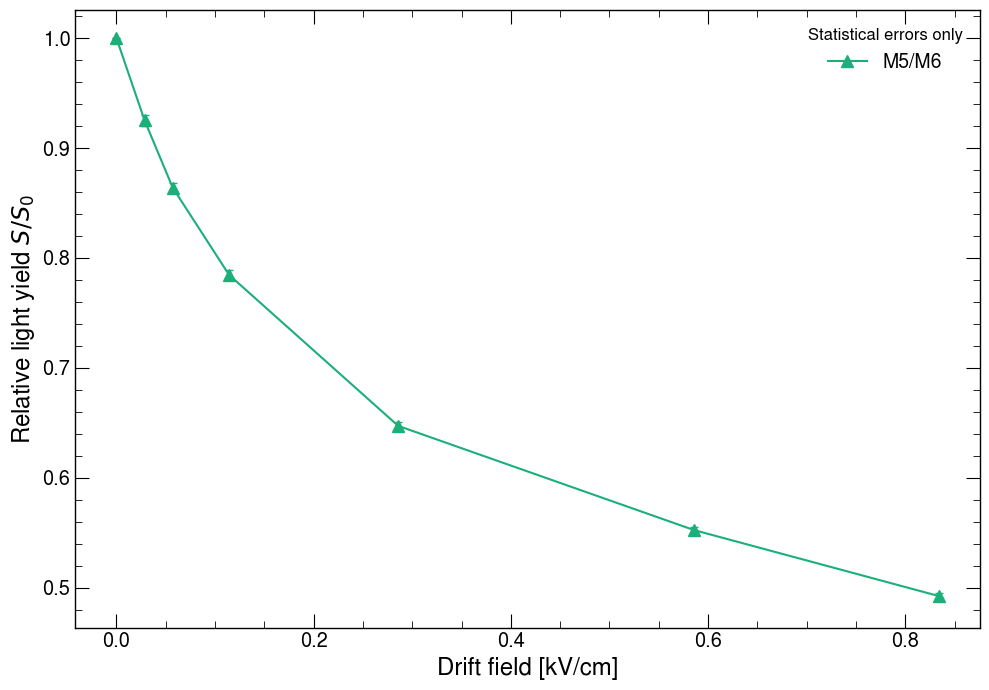

In [77]:
# categorical slots 1-4, one marker per pair so color is not the only cue
PAIR_STYLE = dict(zip(pairs, [("#2a78d6", "o"), ("#eb6834", "s"),
                              ("#1baf7a", "^"), ("#eda100", "D")]))

fig, ax = plt.subplots(figsize=(10, 7), dpi=100)
handles, labels = [], []
for pair, (color, marker) in PAIR_STYLE.items():
    points = ly_pairs[ly_pairs["pair"] == pair]
    if points.empty:
        continue
    ax.plot(points["E"], points["rel"], color=color, linewidth=1.5, zorder=1)
    for complete, face in ((True, color), (False, "white")):
        subset = points[points["complete"] == complete]
        ax.errorbar(subset["E"], subset["rel"], yerr=subset["rel_err"], fmt=marker,
                    color=color, markerfacecolor=face, markersize=8, capsize=3, zorder=2)
    handles.append(plt.Line2D([], [], color=color, marker=marker, markersize=8, linewidth=1.5))
    labels.append(pair)
if not ly_pairs["complete"].all():
    handles.append(plt.Line2D([], [], color="#52514e", marker="o", markerfacecolor="white",
                              markersize=8, linestyle="none"))
    labels.append("fewer channels than at 0 kV")

ax.set_xlabel("Drift field [kV/cm]")
ax.set_ylabel(r"Relative light yield $S/S_0$")
ax.legend(handles, labels, loc="upper right", fontsize=14,
          title="Statistical errors only", title_fontsize=12)
fig.tight_layout()
fig.savefig(OUT_DIR / "relative_ly_pairs.png", dpi=200)
plt.show()

### Channels of each pair

Each channel's $S/S_0$ (thin) and the pair average (black). The gap between the
channels is the `spread` column.

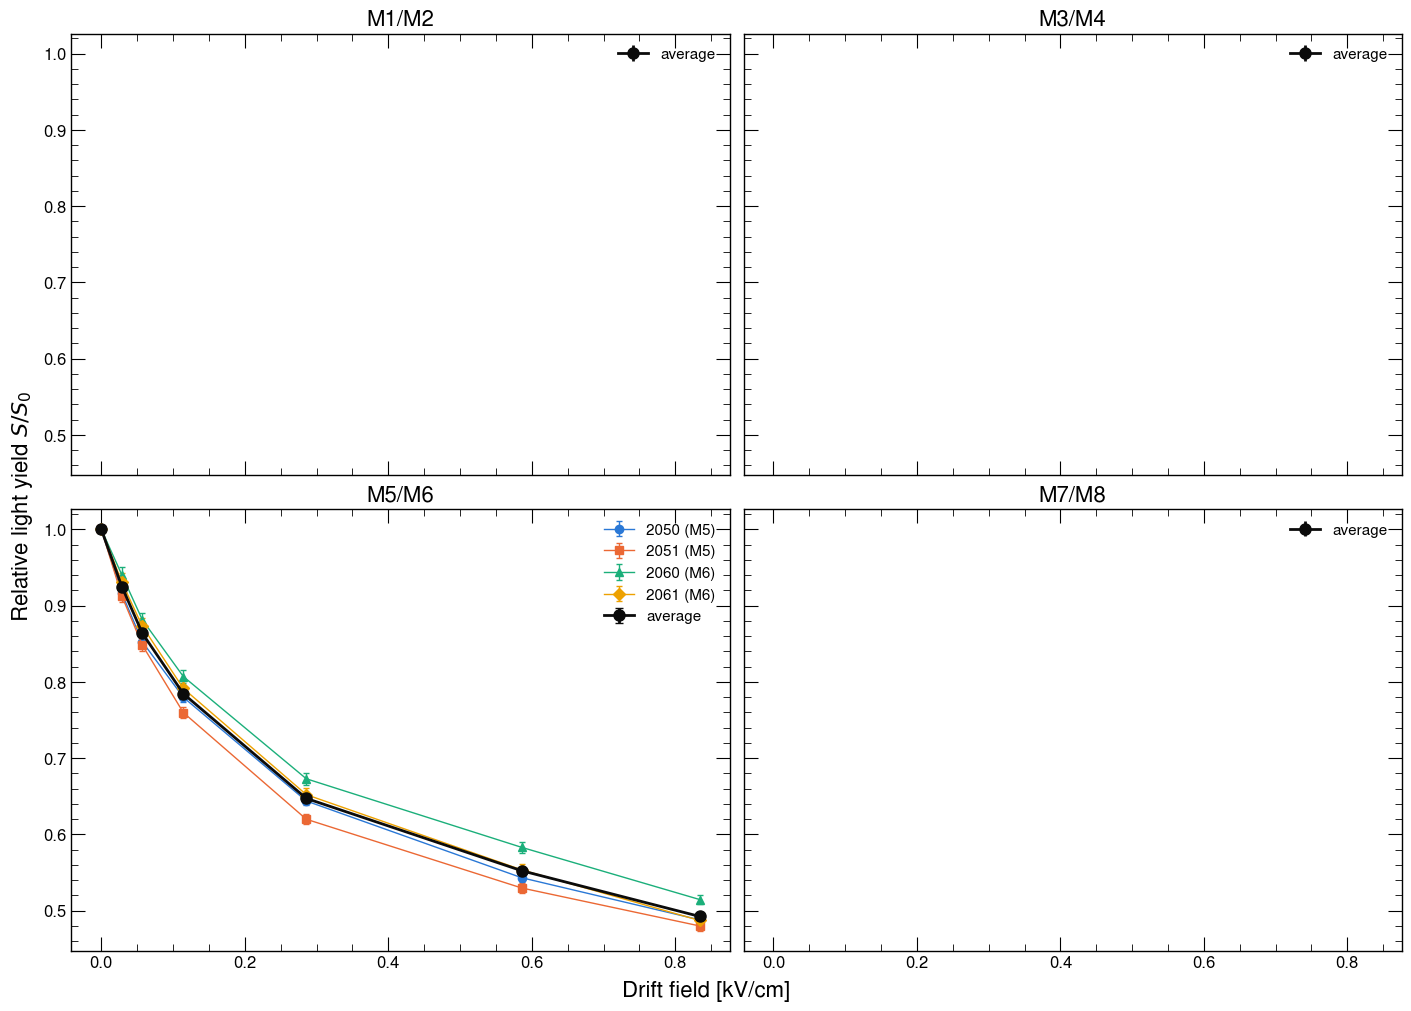

In [78]:
# slot by position in the pair (20k0, 20k1, 20(k+1)0, 20(k+1)1): a channel keeps its color
CHANNEL_SLOTS = [("#2a78d6", "o"), ("#eb6834", "s"), ("#1baf7a", "^"), ("#eda100", "D")]

fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=100, sharex=True, sharey=True,
                         layout="constrained")
for ax, (pair, pair_channels) in zip(axes.flat, pairs.items()):
    for channel, (color, marker) in zip(pair_channels, CHANNEL_SLOTS):
        points = ly_channels[ly_channels["channel"] == channel]
        if points.empty:
            continue
        ax.errorbar(points["E"], points["rel"], yerr=points["rel_err"], fmt=f"{marker}-",
                    color=color, linewidth=1, markersize=6, capsize=2,
                    label=f"{channel} (M{(channel // 10) % 10})")
    average = ly_pairs[ly_pairs["pair"] == pair]
    ax.errorbar(average["E"], average["rel"], yerr=average["rel_err"], fmt="o-",
                color="#0b0b0b", linewidth=2, markersize=8, capsize=3, label="average")
    ax.set_title(pair, fontsize=16)
    ax.tick_params(labelsize=12)
    ax.legend(loc="upper right", fontsize=11)
fig.supxlabel("Drift field [kV/cm]", fontsize=16)
fig.supylabel(r"Relative light yield $S/S_0$", fontsize=16)
fig.savefig(OUT_DIR / "relative_ly_pairs_channels.png", dpi=200)
plt.show()

## One module over the other

$$R(E) = \frac{S_{\mathrm{M}k}(E)}{S_{\mathrm{M}k+1}(E)}$$

for M1/M2, M3/M4, M5/M6 and M7/M8, at each field. Both modules come from the same run, so
anything that changes from run to run for both cancels. $S$ of a module is the mean of its
arrays' mean integrals (the $S$ above).

- A run is used only if every array the module has at 0 kV is in it, so the ratio always
  compares the same channels. Otherwise that field is left out for the pair.
- The level of $R$ depends on each module's gain (ADC, no p.e. calibration).
- Errors are statistical only.

In [79]:
S_by_run = ly_runs.set_index(["channel", "run"])[["S", "S_err"]]

# arrays of each module that have the 0 kV run
module_arrays = {
    module: [channel for channel in (modules.channel(module, 1), modules.channel(module, 2))
             if (channel, REFERENCE_RUN) in S_by_run.index]
    for module in {m for pair in pairs for m in pair.split("/")}
}


def module_S(module, run):
    """(S, error) of a module in a run, None when one of its arrays is missing."""
    arrays = module_arrays[module]
    if not arrays or any((channel, run) not in S_by_run.index for channel in arrays):
        return None
    rows = S_by_run.loc[[(channel, run) for channel in arrays]]
    return rows["S"].mean(), quadrature_mean(rows["S_err"])


ratio_records, left_out = [], []
for pair in pairs:
    top, bottom = pair.split("/")
    for run in runs:
        s_top, s_bottom = module_S(top, run), module_S(bottom, run)
        if s_top is None or s_bottom is None:
            left_out.append(f"{pair} at {run_to_efield[run]:.3f} kV/cm (run {run:06d})")
            continue
        ratio = s_top[0] / s_bottom[0]
        ratio_records.append({
            "pair": pair, "run": run, "E": run_to_efield[run],
            "HV": pds_runs.field_of(f"{run:06d}"),
            "ratio": ratio,
            "ratio_err": ratio * np.hypot(s_top[1] / s_top[0], s_bottom[1] / s_bottom[0]),
        })

# runs at the same field averaged
module_ratios = (
    pd.DataFrame(ratio_records).groupby(["pair", "E"])
    .agg(HV=("HV", "first"), ratio=("ratio", "mean"), ratio_err=("ratio_err", quadrature_mean),
         runs=("run", lambda r: " ".join(f"{x:06d}" for x in sorted(r))))
    .reset_index()
)
module_ratios.to_csv(OUT_DIR / "module_ratio_per_pair.csv", index=False)

for module in sorted(module_arrays):
    print(f"{module}: arrays {module_arrays[module]}")
if left_out:
    print("Left out (a module misses an array):\n  " + "\n  ".join(left_out))

# R = S(Mk)/S(Mk+1) +- statistical error, per pair (rows) and field (columns)
module_ratios.assign(
    field=[f"{e:.3f} kV/cm ({hv:g} kV)" for e, hv in zip(module_ratios["E"], module_ratios["HV"])],
    value=[f"{r:.4f} ± {e:.4f}" for r, e in zip(module_ratios["ratio"], module_ratios["ratio_err"])],
).pivot(index="pair", columns="field", values="value").fillna("")

M1: arrays []
M2: arrays []
M3: arrays []
M4: arrays []
M5: arrays [2050, 2051]
M6: arrays [2060, 2061]
M7: arrays []
M8: arrays []
Left out (a module misses an array):
  M1/M2 at 0.000 kV/cm (run 039510)
  M1/M2 at 0.029 kV/cm (run 039511)
  M1/M2 at 0.057 kV/cm (run 039512)
  M1/M2 at 0.114 kV/cm (run 039515)
  M1/M2 at 0.286 kV/cm (run 039522)
  M1/M2 at 0.586 kV/cm (run 043383)
  M1/M2 at 0.834 kV/cm (run 041523)
  M3/M4 at 0.000 kV/cm (run 039510)
  M3/M4 at 0.029 kV/cm (run 039511)
  M3/M4 at 0.057 kV/cm (run 039512)
  M3/M4 at 0.114 kV/cm (run 039515)
  M3/M4 at 0.286 kV/cm (run 039522)
  M3/M4 at 0.586 kV/cm (run 043383)
  M3/M4 at 0.834 kV/cm (run 041523)
  M7/M8 at 0.000 kV/cm (run 039510)
  M7/M8 at 0.029 kV/cm (run 039511)
  M7/M8 at 0.057 kV/cm (run 039512)
  M7/M8 at 0.114 kV/cm (run 039515)
  M7/M8 at 0.286 kV/cm (run 039522)
  M7/M8 at 0.586 kV/cm (run 043383)
  M7/M8 at 0.834 kV/cm (run 041523)


field,0.000 kV/cm (0 kV),0.029 kV/cm (10 kV),0.057 kV/cm (20 kV),0.114 kV/cm (40 kV),0.286 kV/cm (100 kV),0.586 kV/cm (205 kV),0.834 kV/cm (292 kV)
pair,,,,,,,
M5/M6,1.6765 ± 0.0124,1.6385 ± 0.0114,1.6253 ± 0.0113,1.6155 ± 0.0117,1.5998 ± 0.0127,1.5821 ± 0.0140,1.6188 ± 0.0165


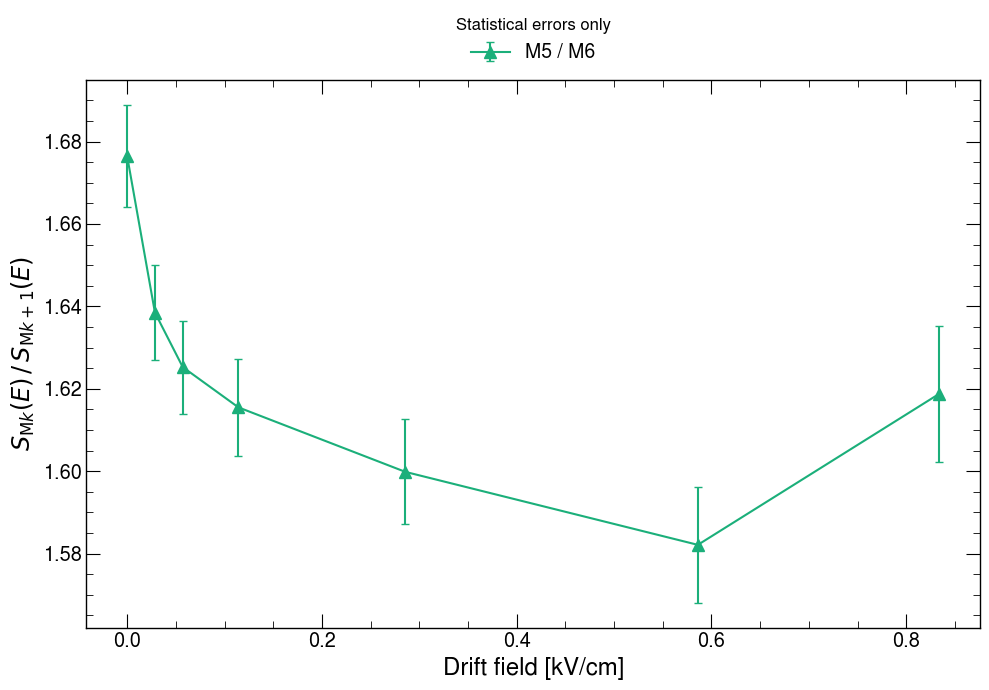

In [80]:
fig, ax = plt.subplots(figsize=(10, 7), dpi=100)
for pair, (color, marker) in PAIR_STYLE.items():
    points = module_ratios[module_ratios["pair"] == pair]
    if points.empty:
        continue
    top, bottom = pair.split("/")
    ax.errorbar(points["E"], points["ratio"], yerr=points["ratio_err"], fmt=f"{marker}-",
                color=color, linewidth=1.5, markersize=8, capsize=3, label=f"{top} / {bottom}")
ax.set_xlabel("Drift field [kV/cm]")
ax.set_ylabel(r"$S_{\mathrm{M}k}(E)\,/\,S_{\mathrm{M}k+1}(E)$")
# above the axes: the four ratios spread over the whole height
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=len(PAIR_STYLE), fontsize=14,
          title="Statistical errors only", title_fontsize=12)
fig.tight_layout()
fig.savefig(OUT_DIR / "module_ratio_pairs.png", dpi=200)
plt.show()

### M5/M6 and M7/M8, normalized at 0 kV

Each pair's ratio divided by its own ratio at 0 kV (run 039510), so both start at 1:

$$\frac{S_{\mathrm{M}k}(E)\,/\,S_{\mathrm{M}k+1}(E)}{S_{\mathrm{M}k}(0)\,/\,S_{\mathrm{M}k+1}(0)}$$

Statistical errors only. The 0 kV point is exactly 1.

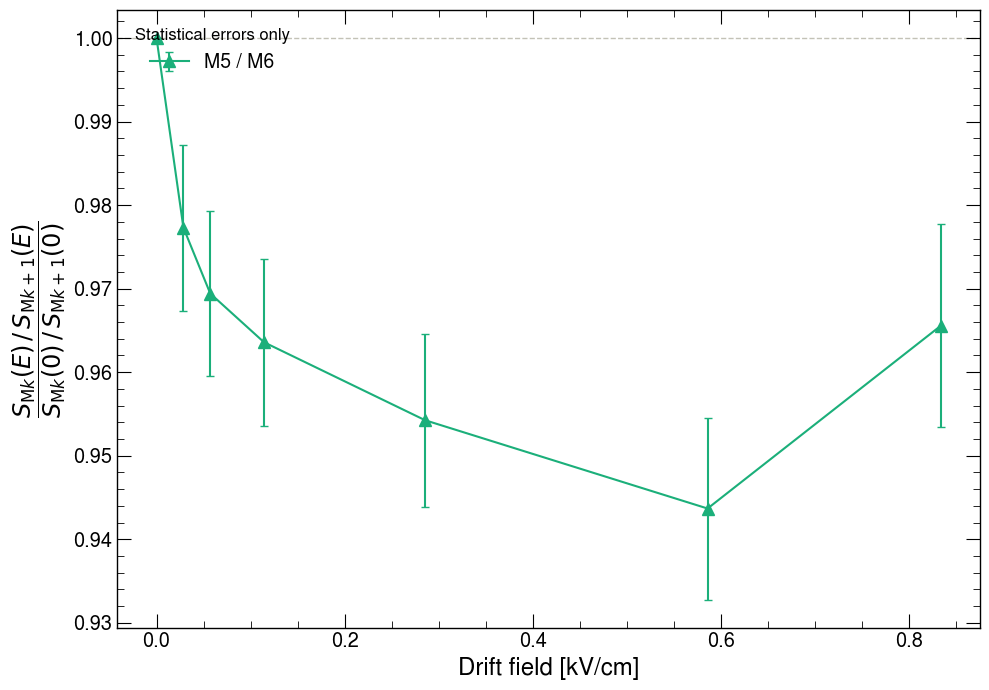

field,0.000 kV/cm (0 kV),0.029 kV/cm (10 kV),0.057 kV/cm (20 kV),0.114 kV/cm (40 kV),0.286 kV/cm (100 kV),0.586 kV/cm (205 kV),0.834 kV/cm (292 kV)
pair,,,,,,,
M5/M6,1.0000 ± 0.0000,0.9773 ± 0.0099,0.9694 ± 0.0098,0.9636 ± 0.0100,0.9542 ± 0.0104,0.9437 ± 0.0109,0.9656 ± 0.0122


In [81]:
COMPARE_PAIRS = ["M5/M6"]

compare = module_ratios[module_ratios["pair"].isin(COMPARE_PAIRS)].copy()
at_zero = compare[compare["E"] == run_to_efield[REFERENCE_RUN]].set_index("pair")
R0 = compare["pair"].map(at_zero["ratio"])
R0_err = compare["pair"].map(at_zero["ratio_err"])
compare["norm"] = compare["ratio"] / R0
compare["norm_err"] = compare["norm"] * np.hypot(compare["ratio_err"] / compare["ratio"], R0_err / R0)
compare.loc[compare["E"] == run_to_efield[REFERENCE_RUN], "norm_err"] = 0.0

fig, ax = plt.subplots(figsize=(10, 7), dpi=100)
ax.axhline(1.0, color="#c3c2b7", linewidth=1, linestyle="--", zorder=0)
for pair in COMPARE_PAIRS:
    color, marker = PAIR_STYLE[pair]   # same color as in the plots above
    points = compare[compare["pair"] == pair]
    top, bottom = pair.split("/")
    ax.errorbar(points["E"], points["norm"], yerr=points["norm_err"], fmt=f"{marker}-",
                color=color, linewidth=1.5, markersize=8, capsize=3, label=f"{top} / {bottom}")
    # min and max of the normalized ratio per pair (1 at 0 kV)

ax.set_xlabel("Drift field [kV/cm]")
ax.set_ylabel(r"$\dfrac{S_{\mathrm{M}k}(E)\,/\,S_{\mathrm{M}k+1}(E)}"
              r"{S_{\mathrm{M}k}(0)\,/\,S_{\mathrm{M}k+1}(0)}$")
ax.legend(loc="upper left", fontsize=14, title="Statistical errors only", title_fontsize=12)
fig.tight_layout()
fig.savefig(OUT_DIR / f"module_ratio_normalized_{'_'.join(p.replace('/', '-') for p in COMPARE_PAIRS)}.png", dpi=200)
# the plotted points: x = field, y and error bar of each curve
plot_data = compare.pivot(index=["E", "HV"], columns="pair", values=["norm", "norm_err"])
plot_data = plot_data.swaplevel(axis=1)[COMPARE_PAIRS]
plot_data.columns = [f"{pair} {value}" for pair, value in plot_data.columns]
plot_data.reset_index().rename(columns={"E": "E [kV/cm]", "HV": "HV [kV]"}).to_csv(
    OUT_DIR / f"module_ratio_normalized_{'_'.join(p.replace('/', '-') for p in COMPARE_PAIRS)}.csv",
    index=False, float_format="%.6g")


plt.show()

# normalized ratio +- statistical error, per pair (rows) and field (columns)
compare.assign(
    field=[f"{e:.3f} kV/cm ({hv:g} kV)" for e, hv in zip(compare["E"], compare["HV"])],
    value=[f"{r:.4f} ± {e:.4f}" for r, e in zip(compare["norm"], compare["norm_err"])],
).pivot(index="pair", columns="field", values="value")

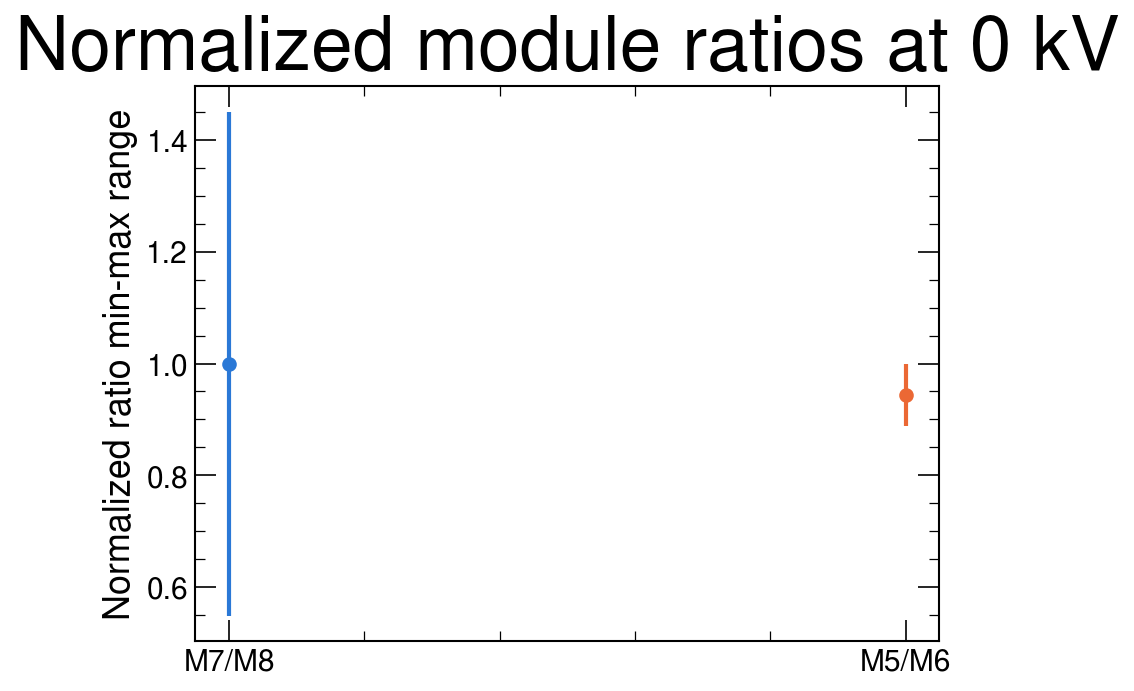

In [57]:
m7_m8 = pd.read_csv("/home/leoperes/pds_analysis/output/analysis/relative_ly/coinc_M3-M4_vs_M5-M6_save_M7-M8_a0_r292kV_aux2000_full12000/module_ratio_normalized_M1-M2_M3-M4_M5-M6_M7-M8_min_max.csv")
m1_m2 = pd.read_csv("/home/leoperes/pds_analysis/output/analysis/relative_ly/coinc_M7-M8_vs_M1-M2_save_M5-M6_a0_r292kV_aux2000_full12000/module_ratio_normalized_M1-M2_M3-M4_M5-M6_M7-M8_min_max.csv")

plt.figure(dpi=150)
plt.errorbar(m7_m8["pair"], m7_m8["min"], yerr=m7_m8["max"] - m7_m8["min"], fmt="o", color="#2a78d6", label="M3/M4 vs M5/M6")
plt.errorbar(m1_m2["pair"], m1_m2["min"], yerr=m1_m2["max"] - m1_m2["min"], fmt="o", color="#eb6834", label="M7/M8 vs M1/M2")
plt.ylabel("Normalized ratio min-max range")
plt.title("Normalized module ratios at 0 kV")           
plt.show()